In [ ]:

import os
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, f1_score

torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Train:", len(train_dataset))
print("Test:", len(test_dataset))


Device: cuda
Train: 60000
Test: 10000


/home/junea/.local/lib/python3.8/site-packages/sklearn/utils/multiclass.py:13: DeprecationWarning: Please use `spmatrix` from the `scipy.sparse` namespace, the `scipy.sparse.base` namespace is deprecated.
  from scipy.sparse.base import spmatrix


In [ ]:
# CNN 모델 정의

import torch
import torch.nn as nn

class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Identity(),                              # conv.0
            nn.Conv2d(1, 16, kernel_size=3, padding=1),  # conv.1
            nn.ReLU(),                                  # conv.2
            nn.Conv2d(16, 32, kernel_size=3, padding=1), # conv.3
            nn.ReLU(),                                  # conv.4
            nn.MaxPool2d(4)                             # conv.5
        )

        self.fc = nn.Linear(32 * 7 * 7, 10)

    def forward(self, x):
        x = self.conv(x)
        x = torch.flatten(x, 1)
        return self.fc(x)


# 기존 학습 가중치 불러오기
original_model = CNN().to(device)

original_model.load_state_dict(
    torch.load(
        "models/mnist_cnn.pth",
        map_location=device,
        weights_only=True
    )
)

original_model.eval()

# 기존 모델 정확도 확인
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = original_model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

accuracy = correct / total * 100

print(f"기존 CNN Accuracy: {accuracy:.2f}%")

기존 CNN Accuracy: 95.16%


In [ ]:
# Fine-tuning 모델 준비

import copy

# 기존 모델과 동일한 가중치에서 시작
finetuned_model = copy.deepcopy(original_model)

finetuned_model = finetuned_model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    finetuned_model.parameters(),
    lr=0.0001
)

epochs = 5
noise_level = 0.5

print("Fine-tuning 모델 준비 완료")


Fine-tuning 모델 준비 완료


In [6]:
# 노이즈 추가 함수

def add_noise(images, noise_level=0.5):
    noise = torch.randn_like(images) * noise_level

    noisy_images = images + noise

    return torch.clamp(noisy_images, 0.0, 1.0)


In [ ]:
# Fine-tuning 학습

# 기존과 다른점
# 기존 outputs = model(images)
# 현재 noisy_images = add_noise(images, 0.5) 
#      outputs = finetuned_model(noisy_images)

# 모델이 강한 노이즈가 포함된 숫자 이미지에서도 정답을 인식하도록 가중치를 추가로 학습

train_losses = []
train_accuracies = []

for epoch in range(epochs):
    finetuned_model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # 노이즈 σ=0.5 추가
        noisy_images = add_noise(images, noise_level)

        # 기울기 초기화
        optimizer.zero_grad()

        # 기존 CNN으로 예측
        outputs = finetuned_model(noisy_images)

        # 정답과 예측 비교
        loss = criterion(outputs, labels)

        # 역전파
        loss.backward()

        # 기존 가중치 업데이트
        optimizer.step()

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    avg_loss = total_loss / total
    accuracy = 100 * correct / total

    train_losses.append(avg_loss)
    train_accuracies.append(accuracy)

    print(
        f"Epoch [{epoch+1}/{epochs}] | "
        f"Loss: {avg_loss:.4f} | "
        f"Accuracy: {accuracy:.2f}%"
    )


Epoch [1/5] | Loss: 0.5799 | Accuracy: 80.76%
Epoch [2/5] | Loss: 0.2924 | Accuracy: 90.39%
Epoch [3/5] | Loss: 0.2335 | Accuracy: 92.29%
Epoch [4/5] | Loss: 0.2022 | Accuracy: 93.42%
Epoch [5/5] | Loss: 0.1879 | Accuracy: 94.00%


In [ ]:
# Fine-tuning 모델 평가

noise_levels = [0.0, 0.1, 0.2, 0.3, 0.5]

results = []

original_model.eval()
finetuned_model.eval()

for level in noise_levels:
    labels_all = []
    original_preds = []
    finetuned_preds = []

    # 동일한 노이즈로 두 모델을 비교
    torch.manual_seed(42)

    with torch.no_grad():
        for images, labels in test_loader:
            noisy_images = add_noise(images, level).to(device)

            original_outputs = original_model(noisy_images)
            finetuned_outputs = finetuned_model(noisy_images)

            original_pred = original_outputs.argmax(dim=1)
            finetuned_pred = finetuned_outputs.argmax(dim=1)

            labels_all.extend(labels.tolist())
            original_preds.extend(original_pred.cpu().tolist())
            finetuned_preds.extend(finetuned_pred.cpu().tolist())

    original_acc = accuracy_score(
        labels_all, original_preds
    ) * 100

    finetuned_acc = accuracy_score(
        labels_all, finetuned_preds
    ) * 100

    original_f1 = f1_score(
        labels_all, original_preds, average="macro"
    ) * 100

    finetuned_f1 = f1_score(
        labels_all, finetuned_preds, average="macro"
    ) * 100

    results.append({
        "noise": level,
        "original_acc": original_acc,
        "finetuned_acc": finetuned_acc,
        "original_f1": original_f1,
        "finetuned_f1": finetuned_f1
    })

    print(
        f"Noise {level:.1f} | "
        f"Original: {original_acc:.2f}% | "
        f"Fine-tuned: {finetuned_acc:.2f}% | "
        f"변화: {finetuned_acc - original_acc:+.2f}%p"
    )


Noise 0.0 | Original: 95.16% | Fine-tuned: 97.78% | 변화: +2.62%p
Noise 0.1 | Original: 94.87% | Fine-tuned: 97.66% | 변화: +2.79%p
Noise 0.2 | Original: 91.28% | Fine-tuned: 97.51% | 변화: +6.23%p
Noise 0.3 | Original: 77.07% | Fine-tuned: 97.11% | 변화: +20.04%p
Noise 0.5 | Original: 43.02% | Fine-tuned: 94.63% | 변화: +51.61%p


/home/junea/.local/lib/python3.8/site-packages/sklearn/metrics/classification.py:1134: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no predicted samples.
  precision = _prf_divide(tp_sum, pred_sum,


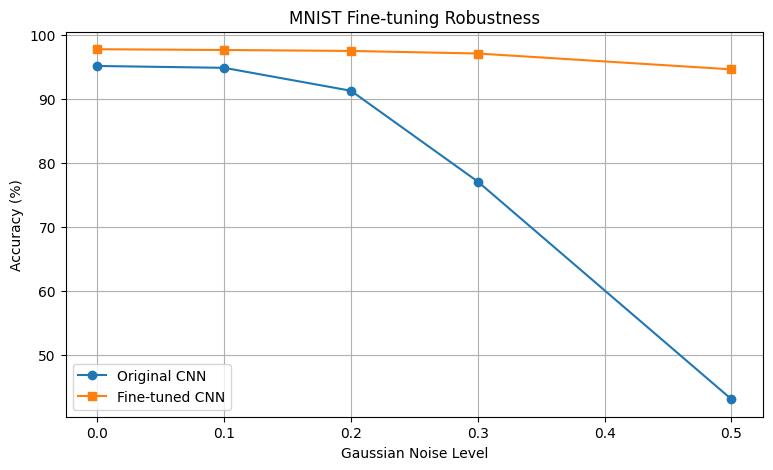

In [ ]:
# 시각화

levels = [r["noise"] for r in results]

original_acc = [
    r["original_acc"] for r in results
]

finetuned_acc = [
    r["finetuned_acc"] for r in results
]

plt.figure(figsize=(9, 5))

plt.plot(
    levels,
    original_acc,
    marker="o",
    label="Original CNN"
)

plt.plot(
    levels,
    finetuned_acc,
    marker="s",
    label="Fine-tuned CNN"
)

plt.xlabel("Gaussian Noise Level")
plt.ylabel("Accuracy (%)")
plt.title("MNIST Fine-tuning Robustness")

plt.legend()
plt.grid(True)
plt.show()


In [10]:
# Fine-tuned CNN 저장

os.makedirs("models", exist_ok=True)

torch.save(
    finetuned_model.state_dict(),
    "models/mnist_cnn_finetuned_05.pth"
)

print("Fine-tuned CNN 저장 완료")


Fine-tuned CNN 저장 완료
